In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/aishu/OneDrive/Desktop/Techsara/Assignment 1/data/Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.shape

(891, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Missing values

In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Cabin"] = df["Cabin"].fillna("Unknown")
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Check remaining missing values
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
LogFare        0
dtype: int64


## Check Duplicates 

In [17]:
df.duplicated().sum()


0

#### There are no duplicates in this dataset

## Checking for outliers

In [7]:
print("Invalid ages:", ((df["Age"] <= 0) | (df["Age"] > 100)).sum())
print("Negative fares:", (df["Fare"] < 0).sum())

df = df[
    (df["Age"] > 0) &
    (df["Age"] <= 100) &
    (df["Fare"] >= 0)
].copy()

Invalid ages: 0
Negative fares: 0


In [18]:
columns = ["Age", "SibSp", "Parch", "Fare"]

for column in columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nColumn:", column)
    print("Number of outliers:", len(outliers))
    print("Outlier values:", sorted(outliers[column].unique()))


Column: Age
Number of outliers: 11
Outlier values: [65.0, 66.0, 70.0, 70.5, 71.0, 74.0, 80.0]

Column: SibSp
Number of outliers: 35
Outlier values: [3, 4, 5]

Column: Parch
Number of outliers: 15
Outlier values: [3, 4, 5, 6]

Column: Fare
Number of outliers: 94
Outlier values: [73.5, 75.25, 76.2917, 76.7292, 77.2875, 77.9583, 78.2667, 78.85, 79.2, 79.65, 80.0, 81.8583, 82.1708, 83.1583, 83.475, 86.5, 89.1042, 90.0, 91.0792, 93.5, 106.425, 108.9, 110.8833, 113.275, 120.0, 133.65, 134.5, 135.6333, 146.5208, 151.55, 153.4625, 164.8667, 211.3375, 211.5, 227.525, 247.5208, 262.375, 263.0, 512.3292]


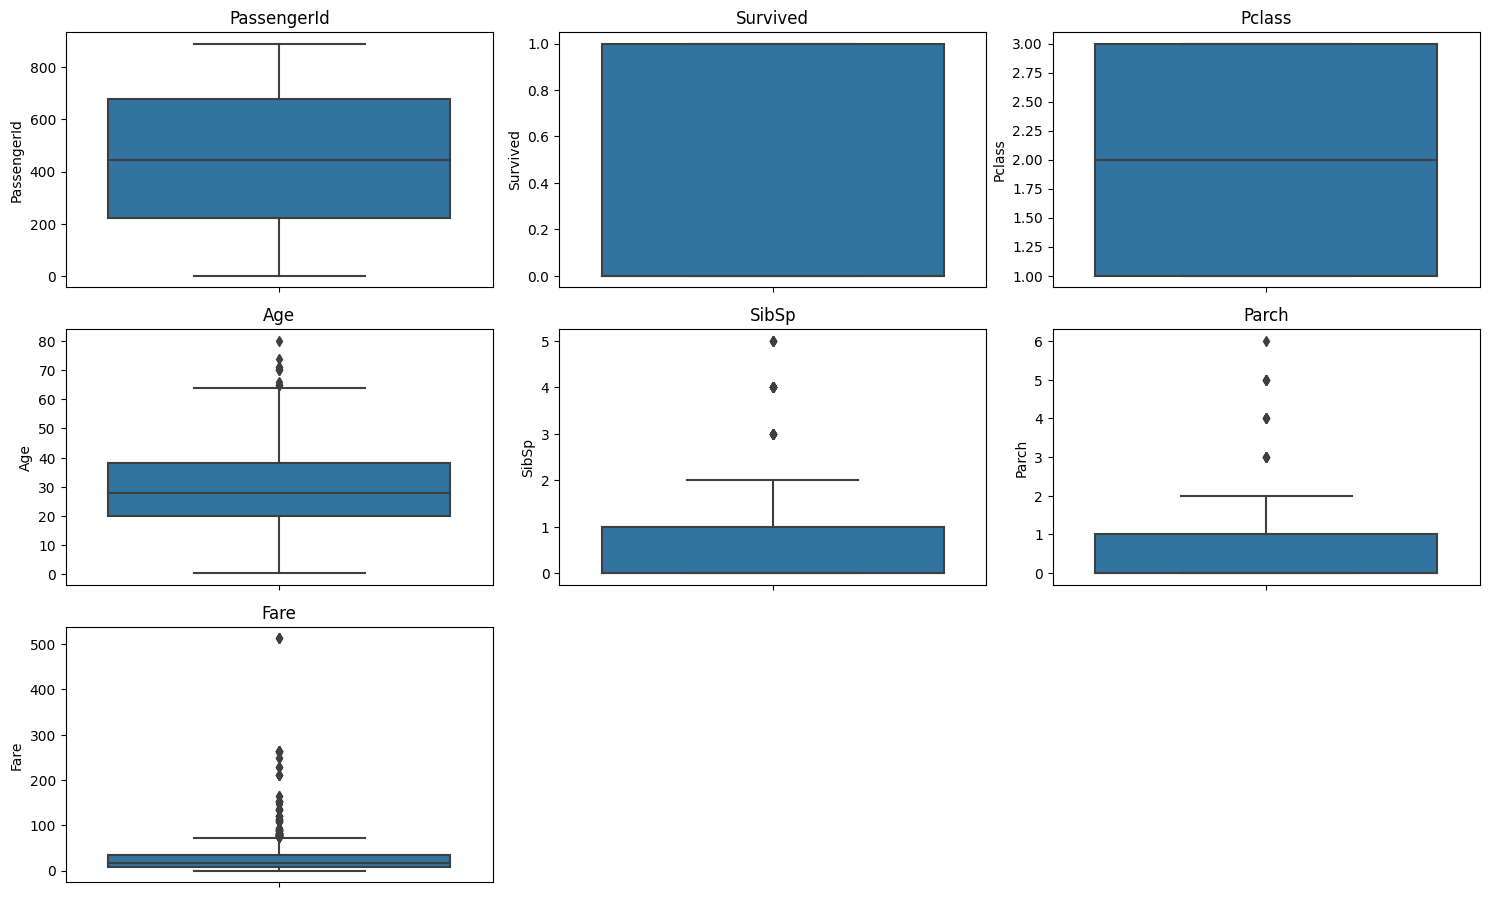

In [17]:
numeric_columns = df.select_dtypes(include="number").columns

plt.figure(figsize=(15, 12))

for i, column in enumerate(numeric_columns):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [ ]:

 # 1. Outliers Identification
for column in ["Age", "SibSp", "Parch", "Fare"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[
        (df[column] < Q1 - 1.5 * IQR) |
        (df[column] > Q3 + 1.5 * IQR)
    ]

    print(column, "- possible outliers:", len(outliers))

# 2. Remove invalid values
rows_before = len(df)

df = df[
    (df["Age"] > 0) &
    (df["Age"] <= 100) &
    (df["SibSp"] >= 0) &
    (df["Parch"] >= 0) &
    (df["Fare"] >= 0)
].copy()

print("Invalid rows removed:", rows_before - len(df))

# 3. Keep plausible ages and large family counts.
# Reduce the effect of high fares using a log transformation.
df["LogFare"] = np.log1p(df["Fare"])

Age - possible outliers: 11
SibSp - possible outliers: 35
Parch - possible outliers: 15
Fare - possible outliers: 94
Invalid rows removed: 0


### I checked Age, SibSp, Parch, and Fare for outliers using the IQR rule. I retained plausible older ages and large family counts. I removed clearly invalid values, if present, and created LogFare to compress high fares without deleting valid passengers.

## Visualization

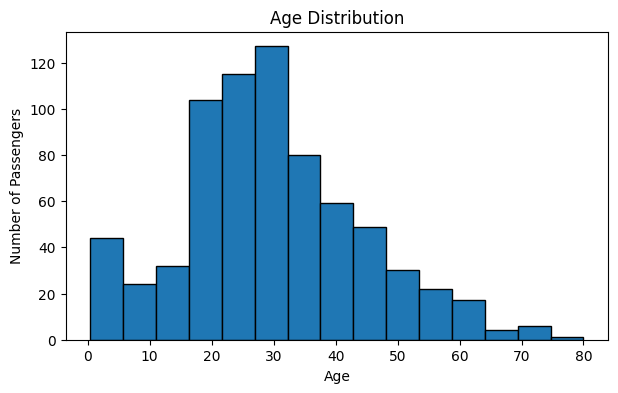

In [ ]:


# Chart 1: Age distribution
plt.figure(figsize=(7, 4))
plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

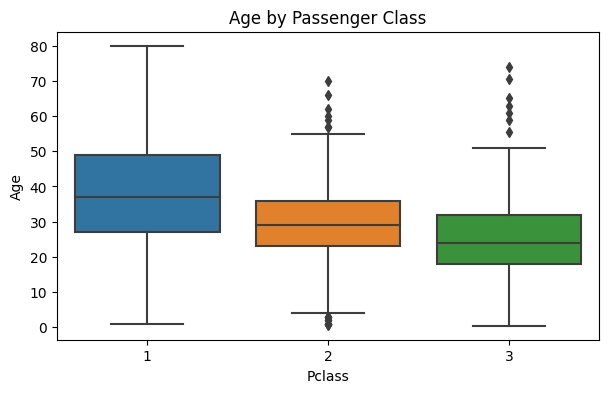

In [14]:
# Chart 2: Age boxplot by passenger class
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Pclass", y="Age")
plt.title("Age by Passenger Class")
plt.show()

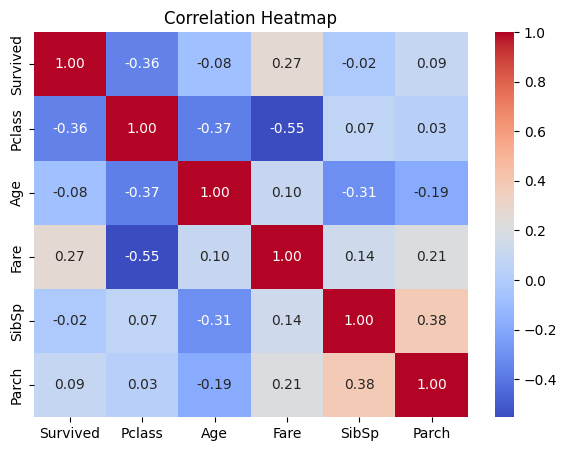

In [15]:
# Chart 3: Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

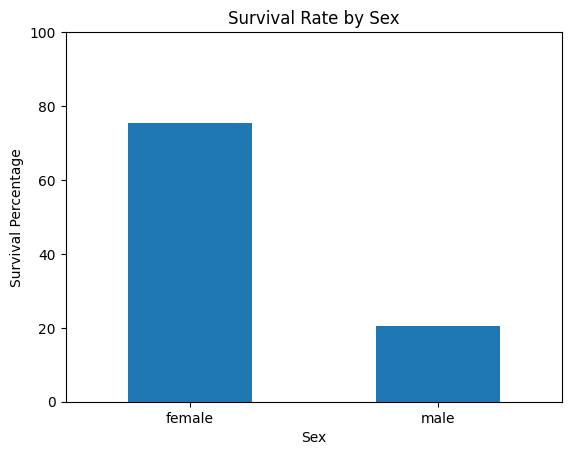

In [16]:
# Chart 4: Compare survival rates by sex
survival = df.groupby("Sex")["Survived"].mean() * 100

survival.plot(kind="bar", rot=0)
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Percentage")
plt.ylim(0, 100)
plt.show()

## Create two new features

In [ ]:
# Total family members aboard, including the passenger
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# 1 = no recorded family aboard, 0 = has recorded family aboard
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print(df[["FamilySize", "IsAlone"]].head())

## My Findings:

- Overall, 40.6% of passengers survived.
- Female survival was 75.5%, compared with 20.5% for males.
- First-class survival was 65%, compared with 24% in third class.
- Passengers with recorded family aboard had 50.6% survival,
  compared with 30.4% for those recorded alone.
- Age had 177 missing values, Cabin had 687, and Embarked had 2.